<a href="https://colab.research.google.com/github/prabhatrm23git/Phishing-email-detection/blob/main/IICT_Project_Phishing_Detection_Full.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI-Driven Phishing Email Detection Using NLP
**IICT Summer Internship Project **

This notebook builds a reproducible email-classification workflow: dataset acquisition, cleaning, exploratory analysis, text and metadata features, four classifiers, model selection, threshold-aware evaluation, interactive prediction, and model export.

**Dataset:** [Phishing Email Dataset — Naser Abdullah Alam (Kaggle)](https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset). The published dataset card describes approximately 82,500 emails from Enron, Ling, CEAS, Nazario, Nigerian Fraud and SpamAssassin. The original files and aggregate have different schemas; this notebook inspects the available files instead of assuming one fixed schema.

**Important:** Dataset labels and source composition can introduce bias. Scores measure performance on this dataset split, not guaranteed real-world protection. A high score should be checked for duplicates and source leakage.

## 1. Environment and imports

In [1]:
# If needed, uncomment:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn nltk joblib kagglehub

import os, re, html, json, warnings, zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", category=FutureWarning)
print("Imports ready.")

Imports ready.


## 2. Download and locate the Kaggle dataset
The dataset is retrieved with KaggleHub. If Kaggle access is unavailable in your environment, download the files from the Kaggle page and set `DATA_DIR` to the folder containing the CSV files.

In [2]:
try:
    import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download(
        "naserabdullahalam/phishing-email-dataset"
    ))
    print("Dataset downloaded to:", DATA_DIR)
except Exception as exc:
    DATA_DIR = Path("data")
    print("Automatic download was not available:", repr(exc))
    print("Place the Kaggle CSV files in:", DATA_DIR.resolve())

csv_files = sorted(DATA_DIR.rglob("*.csv")) if DATA_DIR.exists() else []
print("CSV files found:", len(csv_files))
for p in csv_files:
    print(f" - {p} ({p.stat().st_size / 1e6:.1f} MB)")

Using Colab cache for faster access to the 'phishing-email-dataset' dataset.
Dataset downloaded to: /kaggle/input/phishing-email-dataset
CSV files found: 7
 - /kaggle/input/phishing-email-dataset/CEAS_08.csv (67.9 MB)
 - /kaggle/input/phishing-email-dataset/Enron.csv (45.6 MB)
 - /kaggle/input/phishing-email-dataset/Ling.csv (9.3 MB)
 - /kaggle/input/phishing-email-dataset/Nazario.csv (7.8 MB)
 - /kaggle/input/phishing-email-dataset/Nigerian_Fraud.csv (9.2 MB)
 - /kaggle/input/phishing-email-dataset/SpamAssasin.csv (14.9 MB)
 - /kaggle/input/phishing-email-dataset/phishing_email.csv (106.6 MB)


## 3. Load and standardise source files
The Kaggle collection contains multiple corpora. This loader recognises common column names, standardises email text and labels, and keeps source information for later bias checks. It avoids blindly concatenating the pre-combined aggregate with its component files.

In [3]:
TEXT_CANDIDATES = ["text_combined", "text", "email_text", "email", "body", "message", "content"]
SUBJECT_CANDIDATES = ["subject", "email_subject"]
LABEL_CANDIDATES = ["label", "email_type", "type", "class", "category"]

def first_existing(columns, candidates):
    lookup = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    return None

def normalise_label(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, np.integer, float, np.floating)):
        if value in (0, 1):
            return int(value)
    s = str(value).strip().lower()
    if s in {"1", "phishing", "spam", "malicious", "fraud", "phish", "phishing email"}:
        return 1
    if s in {"0", "legitimate", "legit", "ham", "safe", "safe email", "benign", "not phishing"}:
        return 0
    return np.nan

def load_corpus(path):
    raw = pd.read_csv(path, low_memory=False)
    text_col = first_existing(raw.columns, TEXT_CANDIDATES)
    subject_col = first_existing(raw.columns, SUBJECT_CANDIDATES)
    label_col = first_existing(raw.columns, LABEL_CANDIDATES)
    if label_col is None:
        print(f"Skipping {path.name}: no recognised label column")
        return None
    if text_col is None and subject_col is None:
        print(f"Skipping {path.name}: no recognised text/subject column")
        return None
    body = raw[text_col].fillna("").astype(str) if text_col else ""
    subject = raw[subject_col].fillna("").astype(str) if subject_col else ""
    text = (subject + " " + body).str.strip()
    out = pd.DataFrame({
        "text": text,
        "label": raw[label_col].map(normalise_label),
        "source": path.stem
    })
    out = out.dropna(subset=["label"])
    out["label"] = out["label"].astype(int)
    out = out[out["text"].str.strip().ne("")]
    return out

# Prefer the packaged aggregate when present; otherwise combine individual files.
aggregate = [p for p in csv_files if p.name.lower() == "phishing_email.csv"]
if aggregate:
    frames = [load_corpus(aggregate[0])]
else:
    frames = [load_corpus(p) for p in csv_files]
frames = [f for f in frames if f is not None and len(f)]
if not frames:
    raise FileNotFoundError(
        "No usable labelled CSV found. Download the Kaggle dataset or place its CSV files in ./data."
    )

data = pd.concat(frames, ignore_index=True)
data["label"] = data["label"].astype(int)
print("Loaded rows:", len(data))
display(data.head())
display(data["label"].value_counts().rename(index={0:"Legitimate", 1:"Phishing"}).to_frame("emails"))

Loaded rows: 82485


,text,label,source
0,hpl nom may 25 2001 see attached file hplno 525 xls hplno 525 xls,0,phishing_email
1,nom actual vols 24 th forwarded sabrae zajac hou ect 05 30 2001 12 07 pm enron capital trade resources corp eileen p...,0,phishing_email
2,enron actuals march 30 april 1 201 estimated actuals march 30 2001 flow march 31 2001 flow april 1 2001 teco tap 35 ...,0,phishing_email
3,hpl nom may 30 2001 see attached file hplno 530 xls hplno 530 xls,0,phishing_email
4,hpl nom june 1 2001 see attached file hplno 601 xls hplno 601 xls,0,phishing_email


,emails
label,
Phishing,42890
Legitimate,39595


## 4. Data quality checks and preprocessing

In [4]:
def clean_email(text):
    text = html.unescape(str(text))
    text = re.sub(r"(?is)<(script|style).*?>.*?</\\1>", " ", text)
    text = re.sub(r"(?s)<[^>]+>", " ", text)
    text = re.sub(r"(?i)https?://\\S+|www\\.\\S+", " URLTOKEN ", text)
    text = re.sub(r"\\b[\\w.+-]+@[\\w.-]+\\.[A-Za-z]{2,}\\b", " EMAILTOKEN ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text

data["text_raw"] = data["text"].astype(str)
data["text_clean"] = data["text_raw"].map(clean_email)
data = data[data["text_clean"].str.len() > 0].copy()
before = len(data)
data = data.drop_duplicates(subset=["text_clean", "label"]).reset_index(drop=True)
print(f"Removed exact same-text/same-label duplicates: {before - len(data):,}")
print("Final usable rows:", f"{len(data):,}")
print("Missing values:\n", data[["text_clean", "label", "source"]].isna().sum())
print("Label counts:\n", data["label"].value_counts())

Removed exact same-text/same-label duplicates: 408
Final usable rows: 82,077
Missing values:
 text_clean    0
label         0
source        0
dtype: int64
Label counts:
 label
1    42844
0    39233
Name: count, dtype: int64


## 5. Exploratory data analysis

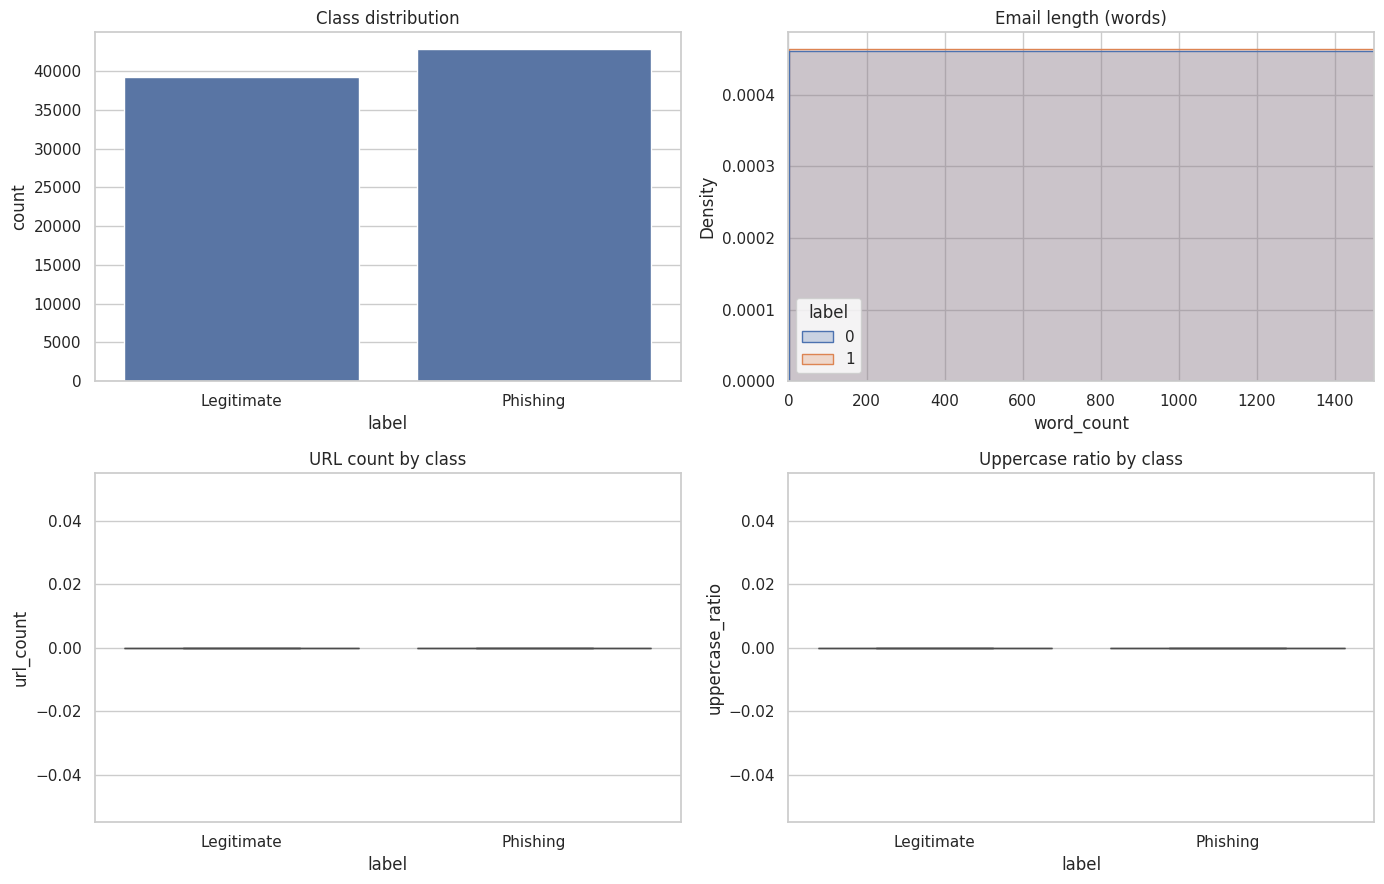

,char_count,word_count,url_count,email_count,exclamation_count,uppercase_ratio
label,,,,,,
Legitimate,780.0,106.0,0.0,0.0,0.0,0.0
Phishing,391.0,55.0,0.0,0.0,0.0,0.0


In [5]:
data["char_count"] = data["text_raw"].str.len()
data["word_count"] = data["text_raw"].str.split().str.len()
data["url_count"] = data["text_raw"].str.count(r"(?i)https?://|www\\.")
data["email_count"] = data["text_raw"].str.count(r"(?i)[\\w.+-]+@[\\w.-]+\\.[A-Za-z]{2,}")
data["exclamation_count"] = data["text_raw"].str.count("!")
data["uppercase_ratio"] = data["text_raw"].map(
    lambda s: sum(ch.isupper() for ch in s) / max(sum(ch.isalpha() for ch in s), 1)
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.countplot(data=data, x="label", ax=axes[0,0])
axes[0,0].set_xticks([0,1], ["Legitimate", "Phishing"])
axes[0,0].set_title("Class distribution")
sns.histplot(data=data, x="word_count", hue="label", bins=50, element="step",
             stat="density", common_norm=False, ax=axes[0,1])
axes[0,1].set_xlim(0, 1500); axes[0,1].set_title("Email length (words)")
sns.boxplot(data=data, x="label", y="url_count", showfliers=False, ax=axes[1,0])
axes[1,0].set_xticks([0,1], ["Legitimate", "Phishing"])
axes[1,0].set_title("URL count by class")
sns.boxplot(data=data, x="label", y="uppercase_ratio", showfliers=False, ax=axes[1,1])
axes[1,1].set_xticks([0,1], ["Legitimate", "Phishing"])
axes[1,1].set_title("Uppercase ratio by class")
plt.tight_layout()
plt.show()

display(data.groupby("label")[["char_count","word_count","url_count","email_count",
                                "exclamation_count","uppercase_ratio"]].median().rename(
    index={0:"Legitimate",1:"Phishing"}
))

### 5.1 Source composition and potential dataset bias

label,legitimate_share,phishing_share
source,,
phishing_email,0.478002,0.521998


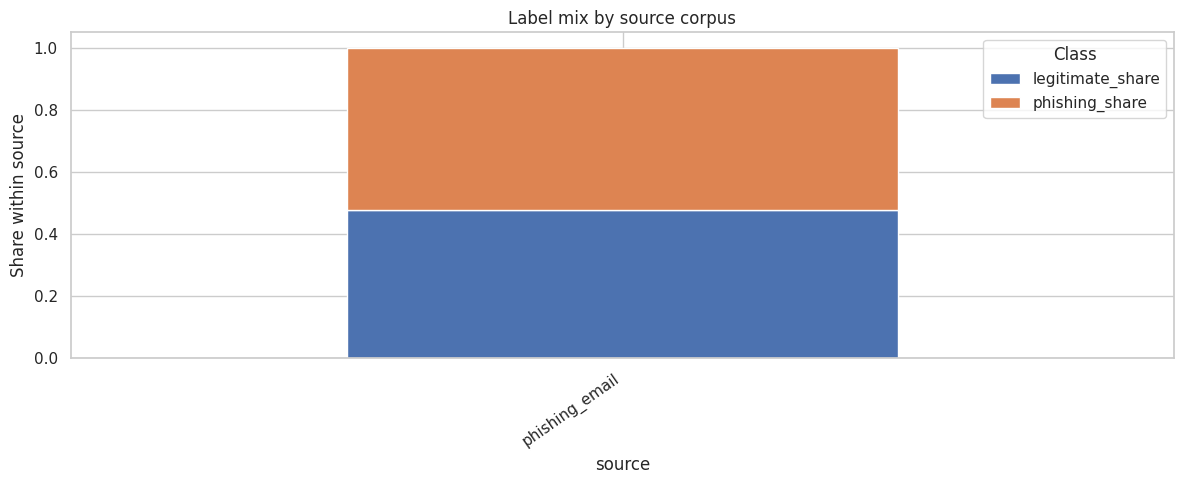

In [6]:
source_table = pd.crosstab(data["source"], data["label"], normalize="index").rename(
    columns={0:"legitimate_share", 1:"phishing_share"}
)
display(source_table.sort_values("phishing_share", ascending=False))
ax = source_table.plot(kind="bar", stacked=True, figsize=(12,5))
ax.set_ylabel("Share within source"); ax.set_title("Label mix by source corpus")
ax.legend(title="Class")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## 6. Metadata feature engineering
We retain the original cleaned text and add simple, explainable structural indicators. URL and email counts are extracted from raw text before URL/email normalisation.

In [7]:
URGENCY_TERMS = [
    "urgent", "immediately", "verify", "suspended", "password", "account",
    "confirm", "update", "security", "limited time", "action required",
    "payment", "invoice", "wire transfer", "click here"
]

def extract_metadata(text):
    s = str(text)
    lower = s.lower()
    letters = [c for c in s if c.isalpha()]
    return {
        "char_count": len(s),
        "word_count": len(s.split()),
        "url_count": len(re.findall(r"(?i)https?://|www\\.", s)),
        "email_count": len(re.findall(r"(?i)[\\w.+-]+@[\\w.-]+\\.[A-Za-z]{2,}", s)),
        "ip_address_count": len(re.findall(r"\\b(?:\\d{1,3}\\.){3}\\d{1,3}\\b", s)),
        "exclamation_count": s.count("!"),
        "question_count": s.count("?"),
        "uppercase_ratio": sum(c.isupper() for c in letters) / max(len(letters), 1),
        "digit_ratio": sum(c.isdigit() for c in s) / max(len(s), 1),
        "urgency_term_count": sum(lower.count(term) for term in URGENCY_TERMS),
        "html_tag_count": len(re.findall(r"<[^>]+>", s))
    }

meta = pd.DataFrame(data["text_raw"].map(extract_metadata).tolist(), index=data.index)
data = pd.concat([data, meta], axis=1)
NUMERIC_FEATURES = list(meta.columns)
display(data[["text_clean"] + NUMERIC_FEATURES].head())

,text_clean,char_count,char_count,word_count,word_count,url_count,url_count,email_count,email_count,ip_address_count,exclamation_count,exclamation_count,question_count,uppercase_ratio,uppercase_ratio,digit_ratio,urgency_term_count,html_tag_count
0,hpl nom may 25 2001 see attached file hplno 525 xls hplno 525 xls,65,65,14,14,0,0,0,0,0,0,0,0,0.0,0.0,0.184615,0,0
1,nom actual vols 24 th forwarded sabrae zajac hou ect 05 30 2001 12 07 pm enron capital trade resources corp eileen p...,1071,1071,208,208,0,0,0,0,0,0,0,0,0.0,0.0,0.126050,0,0
2,enron actuals march 30 april 1 201 estimated actuals march 30 2001 flow march 31 2001 flow april 1 2001 teco tap 35 ...,148,148,28,28,0,0,0,0,0,0,0,0,0.0,0.0,0.189189,0,0
3,hpl nom may 30 2001 see attached file hplno 530 xls hplno 530 xls,65,65,14,14,0,0,0,0,0,0,0,0,0.0,0.0,0.184615,0,0
4,hpl nom june 1 2001 see attached file hplno 601 xls hplno 601 xls,65,65,14,14,0,0,0,0,0,0,0,0,0.0,0.0,0.169231,0,0


## 7. Train/test split and preprocessing
A stratified hold-out test set is kept untouched until final evaluation. TF-IDF is fitted inside each model pipeline, preventing vocabulary leakage from the test set.

In [8]:
X = data[["text_clean"] + NUMERIC_FEATURES].copy()
y = data["label"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train class proportions:\n", y_train.value_counts(normalize=True))

Train: (65661, 18) Test: (16416, 18)
Train class proportions:
 label
1    0.521999
0    0.478001
Name: proportion, dtype: float64


## 8. Train four classifiers
Naive Bayes uses a text-only TF-IDF pipeline because its Multinomial likelihood expects non-negative features. The other models combine TF-IDF text features with scaled metadata.

In [11]:
# Keep only unique columns in our train and test sets to resolve the duplicate column names error
X_train = X_train.loc[:, ~X_train.columns.duplicated()].copy()
X_test = X_test.loc[:, ~X_test.columns.duplicated()].copy()

def make_preprocessor(include_metadata=True, max_features=30000):
    transformers = [
        ("tfidf", TfidfVectorizer(
            max_features=max_features, ngram_range=(1,2),
            min_df=2, max_df=0.98, sublinear_tf=True,
            stop_words="english"
        ), "text_clean")
    ]
    if include_metadata:
        transformers.append((
            "meta",
            Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler(with_mean=False))]),
            NUMERIC_FEATURES
        ))
    return ColumnTransformer(transformers, remainder="drop")

models = {
    "Logistic Regression": Pipeline([
        ("features", make_preprocessor()),
        ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced",
                                           random_state=RANDOM_STATE))
    ]),
    "Naive Bayes": Pipeline([
        ("features", make_preprocessor(include_metadata=False)),
        ("classifier", MultinomialNB(alpha=0.5))
    ]),
    "Random Forest": Pipeline([
        ("features", make_preprocessor(max_features=20000)),
        ("classifier", RandomForestClassifier(
            n_estimators=250, min_samples_leaf=2, class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ]),
    "Neural Network (MLP)": Pipeline([
        ("features", make_preprocessor(max_features=20000)),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(128, 64), alpha=1e-4, batch_size=256,
            early_stopping=True, max_iter=35, random_state=RANDOM_STATE
        ))
    ])
}

fitted_models = {}
rows = []
for name, estimator in models.items():
    print(f"Training {name} ...")
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    score = estimator.predict_proba(X_test)[:,1] if hasattr(estimator, "predict_proba") else None
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, score) if score is not None else np.nan
    })
    fitted_models[name] = estimator

results = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
display(results.style.format({c:"{:.4f}" for c in results.columns if c != "Model"}))

Training Logistic Regression ...
Training Naive Bayes ...
Training Random Forest ...
Training Neural Network (MLP) ...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Neural Network (MLP),0.9898,0.9897,0.9908,0.9903,0.9992
1,Logistic Regression,0.9879,0.9856,0.9914,0.9885,0.9990
2,Random Forest,0.9856,0.9849,0.9875,0.9862,0.9989
3,Naive Bayes,0.9703,0.9911,0.9516,0.9709,0.9977


## 9. Model comparison visualisations

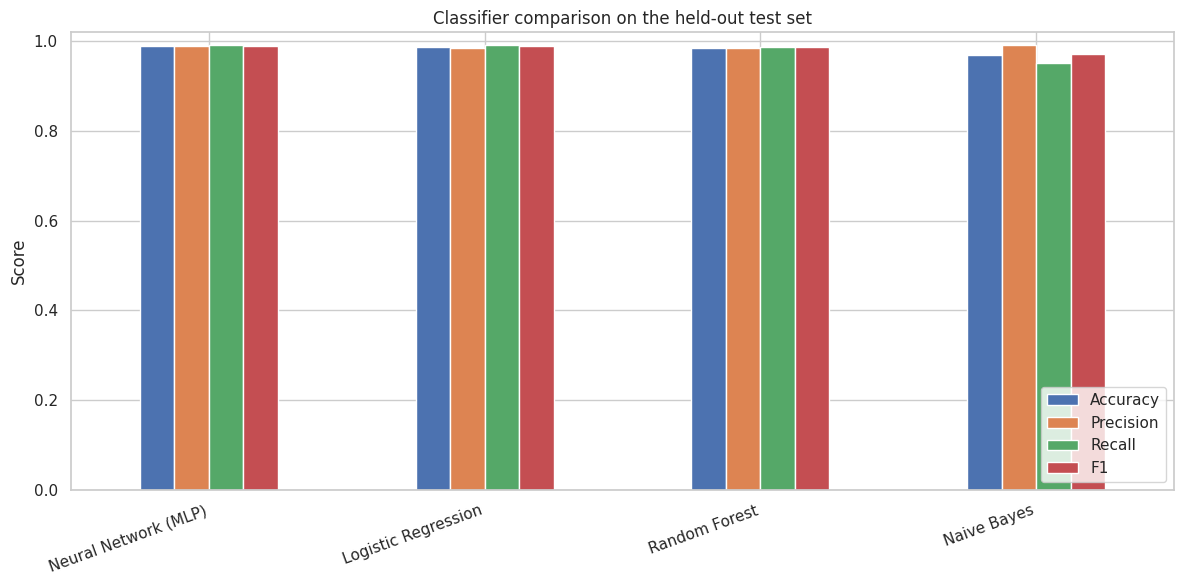

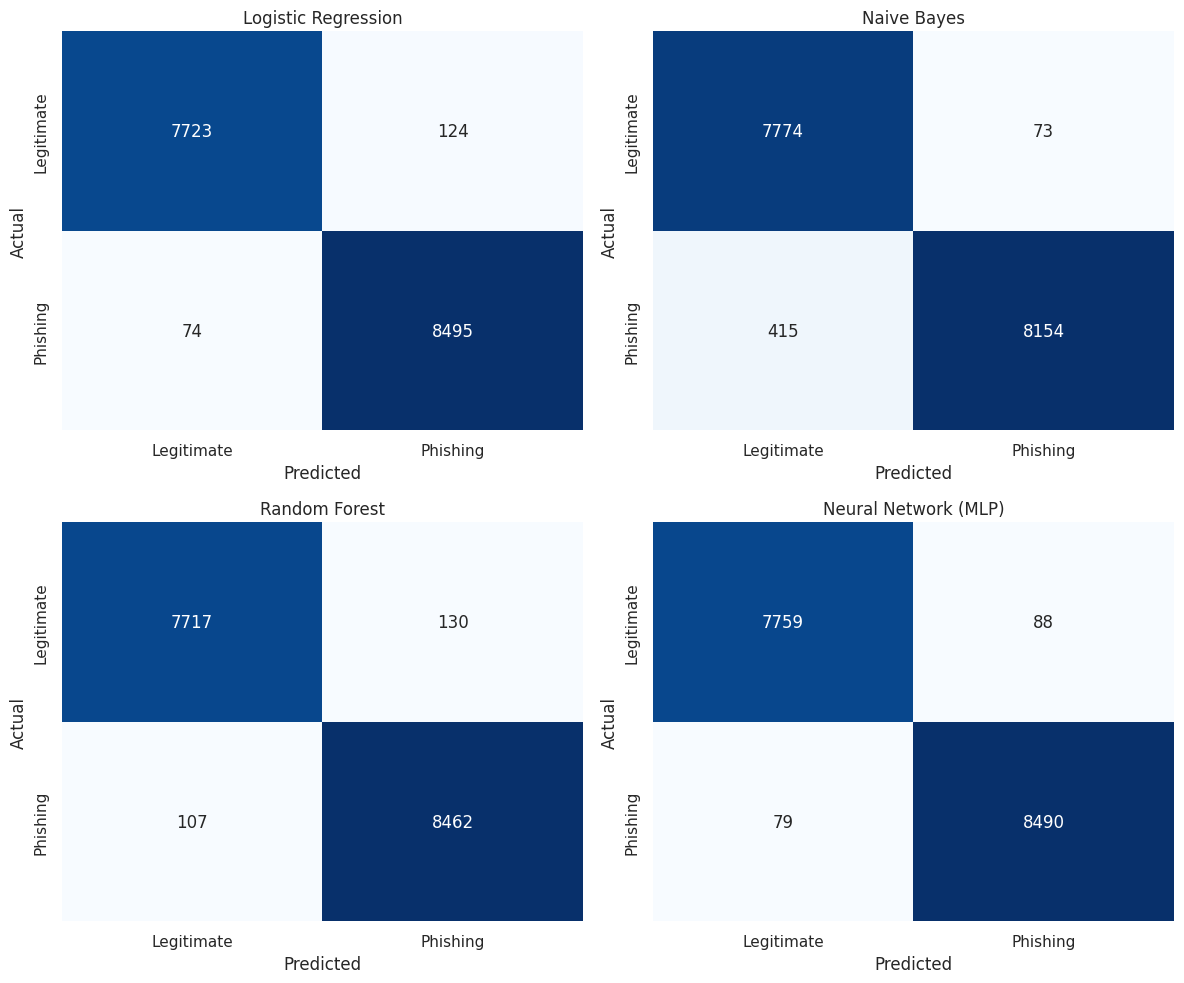

<Figure size 800x600 with 0 Axes>

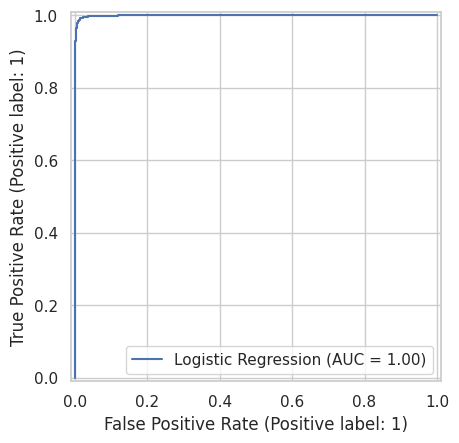

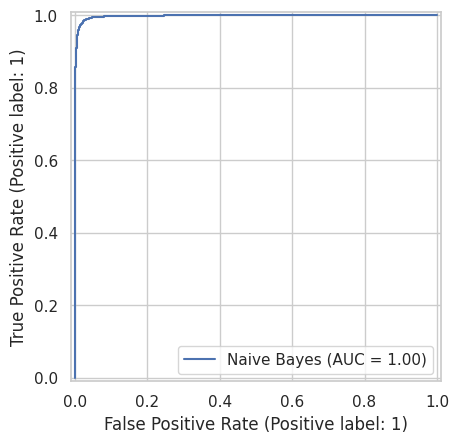

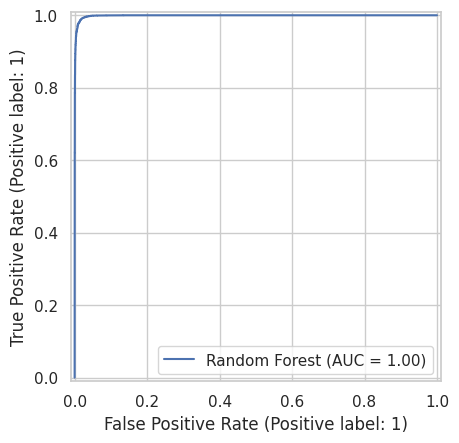

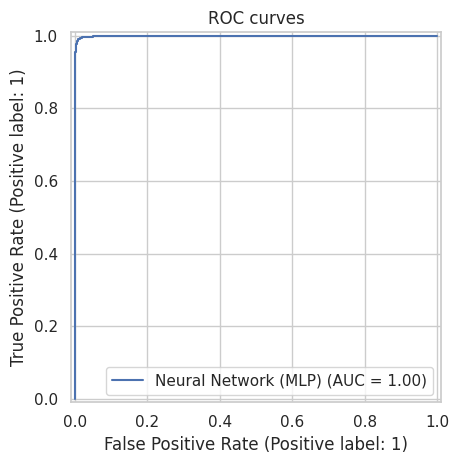

In [12]:
plot_results = results.set_index("Model")[["Accuracy","Precision","Recall","F1"]]
ax = plot_results.plot(kind="bar", figsize=(12,6), ylim=(0,1.02))
ax.set_title("Classifier comparison on the held-out test set")
ax.set_ylabel("Score"); ax.set_xlabel("")
plt.xticks(rotation=20, ha="right"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2,2, figsize=(12,10))
for ax, (name, model) in zip(axes.ravel(), fitted_models.items()):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_xticklabels(["Legitimate","Phishing"]); ax.set_yticklabels(["Legitimate","Phishing"])
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,6))
for name, model in fitted_models.items():
    if hasattr(model, "predict_proba"):
        RocCurveDisplay.from_estimator(model, X_test, y_test, name=name)
plt.title("ROC curves"); plt.tight_layout(); plt.show()

## 10. Hyperparameter tuning
Tune Logistic Regression as a strong, interpretable baseline. Grid search uses only the training partition with stratified cross-validation; the test set remains untouched.

In [13]:
tuning_pipeline = Pipeline([
    ("features", make_preprocessor(max_features=30000)),
    ("classifier", LogisticRegression(max_iter=1800, class_weight="balanced",
                                      random_state=RANDOM_STATE))
])
param_grid = {
    "features__tfidf__ngram_range": [(1,1), (1,2)],
    "features__tfidf__max_features": [20000, 40000],
    "classifier__C": [0.5, 1.0, 2.0, 4.0]
}
search = GridSearchCV(
    tuning_pipeline, param_grid, scoring="f1",
    cv=3, n_jobs=-1, verbose=1, refit=True
)
search.fit(X_train, y_train)
print("Best CV F1:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)
best_model = search.best_estimator_
tuned_pred = best_model.predict(X_test)
tuned_prob = best_model.predict_proba(X_test)[:,1]
print(classification_report(y_test, tuned_pred, target_names=["Legitimate","Phishing"]))
print("Test ROC-AUC:", round(roc_auc_score(y_test, tuned_prob), 4))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best CV F1: 0.9896
Best parameters: {'classifier__C': 4.0, 'features__tfidf__max_features': 40000, 'features__tfidf__ngram_range': (1, 2)}
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      7847
    Phishing       0.99      0.99      0.99      8569

    accuracy                           0.99     16416
   macro avg       0.99      0.99      0.99     16416
weighted avg       0.99      0.99      0.99     16416

Test ROC-AUC: 0.9994


## 11. Precision-recall analysis and threshold selection
The default 0.50 threshold is not always appropriate. Choose a threshold using validation data, not the final test set. This section creates a validation split from the training partition.

Validation-selected threshold: 0.49


,threshold,precision,recall,f1
39,0.49,0.989233,0.991831,0.99053


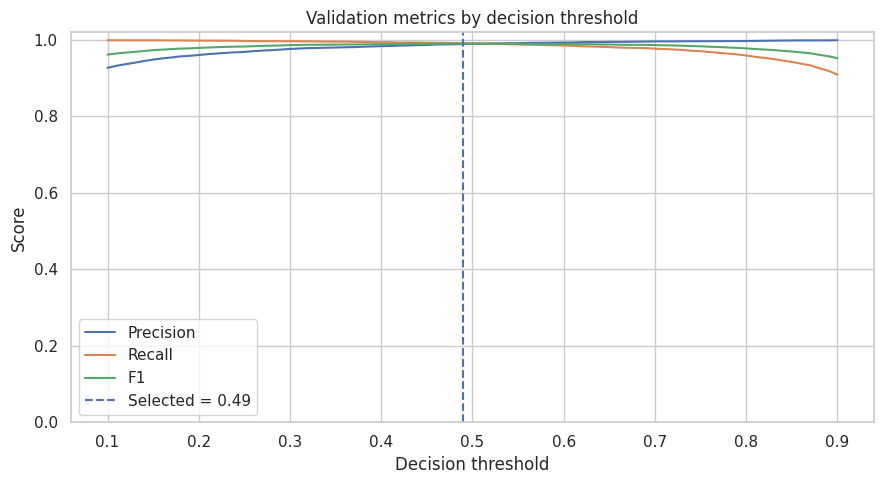

In [14]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train
)
validation_model = clone(best_model)
validation_model.fit(X_fit, y_fit)
val_prob = validation_model.predict_proba(X_val)[:,1]
thresholds = np.linspace(0.10, 0.90, 81)
threshold_rows = []
for threshold in thresholds:
    p = (val_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_val, p, zero_division=0),
        "recall": recall_score(y_val, p, zero_division=0),
        "f1": f1_score(y_val, p, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_rows)
best_threshold = float(threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"])
print("Validation-selected threshold:", round(best_threshold, 3))
display(threshold_df.iloc[[threshold_df["f1"].idxmax()]])
plt.figure(figsize=(9,5))
plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1")
plt.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("Score"); plt.ylim(0,1.02)
plt.title("Validation metrics by decision threshold"); plt.legend()
plt.tight_layout(); plt.show()

## 12. Final held-out evaluation
Refit the tuned model on all training data, then evaluate once on the held-out test set using the selected validation threshold.

,Test score
Accuracy,0.9907
Precision,0.9886
Recall,0.9937
F1-score,0.9912
ROC-AUC,0.9994


              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      7847
    Phishing       0.99      0.99      0.99      8569

    accuracy                           0.99     16416
   macro avg       0.99      0.99      0.99     16416
weighted avg       0.99      0.99      0.99     16416



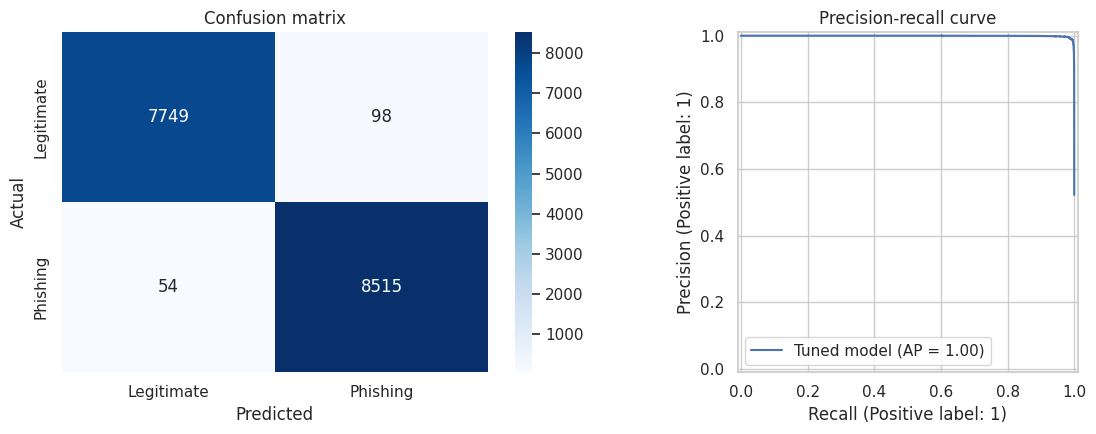

In [15]:
best_model.fit(X_train, y_train)
test_prob = best_model.predict_proba(X_test)[:,1]
test_pred = (test_prob >= best_threshold).astype(int)

final_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1-score": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob)
}
display(pd.DataFrame([final_metrics]).T.rename(columns={0:"Test score"}).style.format("{:.4f}"))
print(classification_report(y_test, test_pred, target_names=["Legitimate","Phishing"]))
fig, axes = plt.subplots(1,2, figsize=(12,4.5))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Legitimate","Phishing"], yticklabels=["Legitimate","Phishing"], ax=axes[0])
axes[0].set_title("Confusion matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[1], name="Tuned model")
axes[1].set_title("Precision-recall curve")
plt.tight_layout(); plt.show()

## 13. Interpreting the model

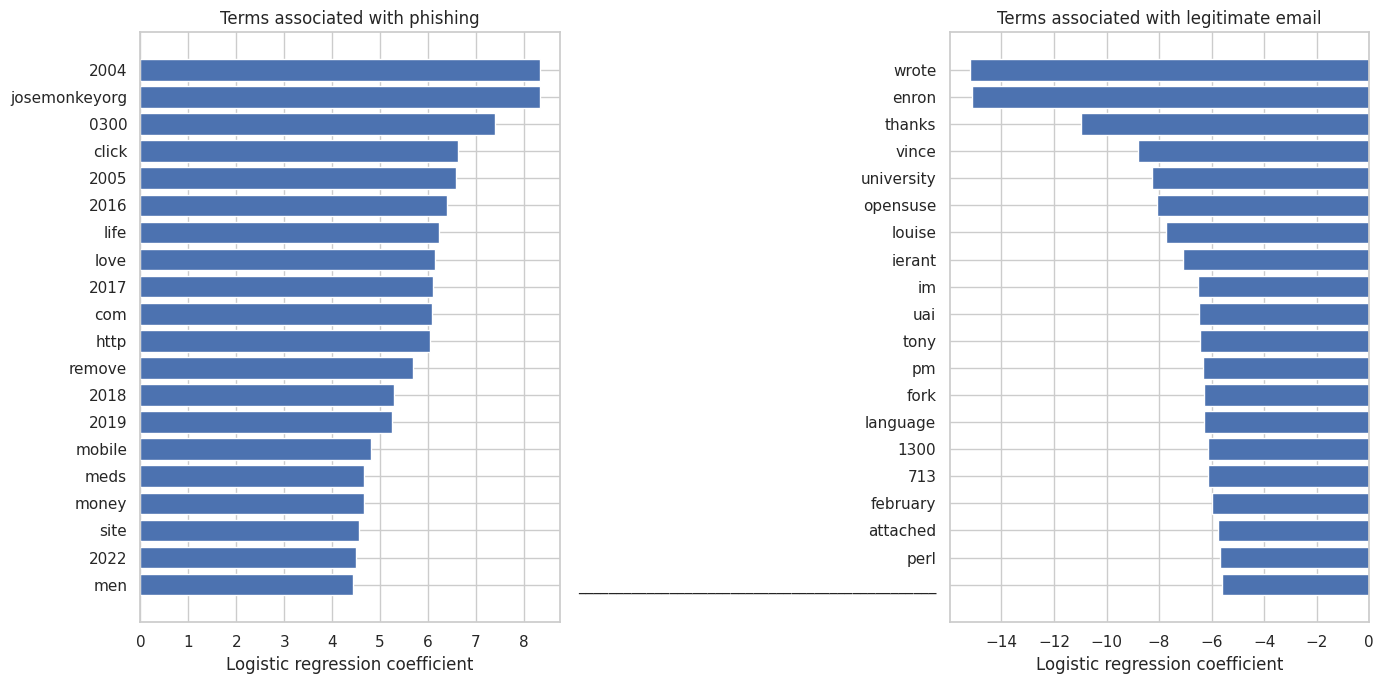

In [16]:
# Logistic regression coefficients are interpretable as direction/strength of association.
# This uses the tuned logistic-regression pipeline.
vec = best_model.named_steps["features"].named_transformers_["tfidf"]
feature_names = list(vec.get_feature_names_out())
coef = best_model.named_steps["classifier"].coef_.ravel()
top_phish = np.argsort(coef)[-20:][::-1]
top_legit = np.argsort(coef)[:20]

fig, axes = plt.subplots(1,2, figsize=(14,7))
axes[0].barh([feature_names[i] for i in top_phish][::-1], coef[top_phish][::-1])
axes[0].set_title("Terms associated with phishing")
axes[0].set_xlabel("Logistic regression coefficient")
axes[1].barh([feature_names[i] for i in top_legit][::-1], coef[top_legit][::-1])
axes[1].set_title("Terms associated with legitimate email")
axes[1].set_xlabel("Logistic regression coefficient")
plt.tight_layout(); plt.show()

## 14. Live email prediction

In [17]:
def predict_email(email_text, threshold=best_threshold):
    raw = str(email_text)
    cleaned = clean_email(raw)
    row = {"text_clean": cleaned}
    row.update(extract_metadata(raw))
    sample = pd.DataFrame([row])
    probability = float(best_model.predict_proba(sample)[0,1])
    label = "PHISHING" if probability >= threshold else "LEGITIMATE"
    return {
        "prediction": label,
        "phishing_probability": round(probability, 4),
        "decision_threshold": round(float(threshold), 3),
        "metadata": {k: row[k] for k in NUMERIC_FEATURES}
    }

sample_phishing = """Subject: Urgent account verification
Your account access will be suspended. Verify your password immediately:
http://example.invalid/secure-login"""

sample_legitimate = """Subject: Team meeting agenda
Hello team, our weekly project meeting is scheduled for Thursday at 10 AM.
Please review the attached agenda before the meeting."""

print("Example 1:", json.dumps(predict_email(sample_phishing), indent=2))
print("Example 2:", json.dumps(predict_email(sample_legitimate), indent=2))

Example 1: {
  "prediction": "PHISHING",
  "phishing_probability": 1.0,
  "decision_threshold": 0.49,
  "metadata": {
    "char_count": 145,
    "word_count": 15,
    "url_count": 1,
    "email_count": 0,
    "ip_address_count": 0,
    "exclamation_count": 0,
    "question_count": 0,
    "uppercase_ratio": 0.03278688524590164,
    "digit_ratio": 0.0,
    "urgency_term_count": 7,
    "html_tag_count": 0
  }
}
Example 2: {
  "prediction": "PHISHING",
  "phishing_probability": 1.0,
  "decision_threshold": 0.49,
  "metadata": {
    "char_count": 157,
    "word_count": 25,
    "url_count": 0,
    "email_count": 0,
    "ip_address_count": 0,
    "exclamation_count": 0,
    "question_count": 0,
    "uppercase_ratio": 0.05511811023622047,
    "digit_ratio": 0.012738853503184714,
    "urgency_term_count": 0,
    "html_tag_count": 0
  }
}


## 15. Save model and supporting artefacts

In [18]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

joblib.dump(best_model, ARTIFACT_DIR / "phishing_email_detector.joblib")
joblib.dump({
    "threshold": best_threshold,
    "numeric_features": NUMERIC_FEATURES,
    "label_mapping": {0:"Legitimate", 1:"Phishing"},
    "dataset": "Naser Abdullah Alam — Kaggle Phishing Email Dataset",
    "random_state": RANDOM_STATE
}, ARTIFACT_DIR / "model_metadata.joblib")
results.to_csv(ARTIFACT_DIR / "model_comparison.csv", index=False)
pd.DataFrame([final_metrics]).to_csv(ARTIFACT_DIR / "final_test_metrics.csv", index=False)

print("Saved files:")
for p in sorted(ARTIFACT_DIR.iterdir()):
    print(p, f"({p.stat().st_size:,} bytes)")

# Verify the saved model can be reloaded and used.
reloaded_model = joblib.load(ARTIFACT_DIR / "phishing_email_detector.joblib")
print("Reload test:", reloaded_model.predict_proba(
    pd.DataFrame([{
        "text_clean": clean_email(sample_phishing),
        **extract_metadata(sample_phishing)
    }])
)[0,1])

Saved files:
artifacts/final_test_metrics.csv (137 bytes)
artifacts/model_comparison.csv (487 bytes)
artifacts/model_metadata.joblib (369 bytes)
artifacts/phishing_email_detector.joblib (1,946,794 bytes)
Reload test: 0.9999996622401415


## 16. Results discussion and limitations

Complete this section after running the notebook and inspecting the measured outputs.

Discuss:
- Which model achieved the strongest F1-score and ROC-AUC?
- Did the tuned Logistic Regression improve over its untuned baseline?
- How did the selected threshold change the precision/recall balance?
- Which words and metadata indicators were most influential?
- Did performance differ across source corpora?

**Limitations:** The dataset is assembled from historical corpora and may contain duplicated or source-specific patterns. A random split can overestimate generalisation when similar emails or source-specific writing styles occur in both train and test sets. A stronger follow-up evaluation would use source-held-out or time-based testing, plus a newer independent dataset. The classifier does not verify sender authenticity, inspect attachments, or query URL reputation services. It is a screening aid, not a replacement for security controls.

## References
1. Naser Abdullah Alam, *Phishing Email Dataset*, Kaggle: https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset
2. Al-Subaiey et al. (2024), *Novel Interpretable and Robust Web-based AI Platform for Phishing Email Detection*, arXiv: https://arxiv.org/abs/2405.11619